In [1]:
from scipy.io import loadmat
import mat73

from tqdm.notebook import tqdm
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
from matplotlib import colorbar as mbar
import seaborn as sns

from scipy.ndimage import gaussian_filter as smooth

from scipy.stats import permutation_test

from sklearn.metrics.pairwise import cosine_similarity as cosine
from scipy.stats import pearsonr as pearson
from scipy.stats import spearmanr as spearman
from scipy.stats import kendalltau as kendall

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

## Definitions ##

In [2]:
def mk_repmat_kernel(input_ls, plot_kernel=False):
    '''
    Args:
        input_ls:    list with the number of samples per condition, i.e., 
                     the list size is the number of categories
        plot_kernel: if True, the created kernel will be plotted
    Returns:
        kernel: (N,N) theoretical ground-truth representatational matrix,
                where N is the total number of samples
    '''

    kernel = np.zeros([sum(input_ls),sum(input_ls)])
    counter_ind = 0
    for i in input_ls:
        inds = np.arange(counter_ind, counter_ind+i)
        counter_ind += i
        kernel[np.ix_(inds,inds)] = 1
        
    if plot_kernel:
        plt.figure(figsize=(2,2))
        plt.imshow(kernel, cmap='coolwarm')
        plt.axis('off')

    return kernel


def mk_repmat_data(input_data, sim_method='cosine', print_info=False):
    '''
    Args:
        input_data: matrix of input data, with shape (Neurons,Stimuli)
        sim_method: method for creating representatational matrix
                    cosine, for cosine similarity
                    spearman, for spearman correlation 
        print_info: if True, the progression will be printed
    Returns:
        repmat: (N,N) representatational matrix, where N is the total number of samples
    '''

    if sim_method=='cosine':
        repmat = cosine(input_data.T)
    elif sim_method=='spearman':
        CorRows = []
        for stim_i in range(input_data.shape[1]):
            CorCols = []
            for stim_j in range(input_data.shape[1]):
                CorCols.append(spearman(input_data[:,stim_i], input_data[:,stim_j])[0])

                if print_info:
                    print('stim_i: ' + str(((stim_i+1)/input_data.shape[1])*100) +
                          ' | ' + 'stim_j: ' + str(((stim_j+1)/input_data.shape[1])*100))

            CorRows.append(CorCols)
        repmat = np.array(CorRows)
    
    return repmat


def plot_repmat(input_repmat, plot_sz=3, show_clb=False, titles=[], colormap='coolwarm', cbar_label='Cosine Similarity (au)', fig_title=''):
    '''
    Args:
        input_repmat: (M,N,N) representatational matrices, where M is the number of conditions and
                      N is the total number of samples
        plot_sz:      size of the generated plot
        show_clb:     if True, colorbar will be shown
        titles:       list of titles of each representatational matrix
        colormap:     colormap for the generated plot
        cbar_label:   colorbar label
    Returns:
        none
    '''

    if not titles: titles=['']*len(input_repmat)
    if show_clb==True:
        fig, axs = plt.subplots(nrows=1, ncols=len(input_repmat)+1, figsize=(3*plot_sz,plot_sz),  dpi=500)
    else:
        fig, axs = plt.subplots(nrows=1, ncols=len(input_repmat), figsize=(3*plot_sz,plot_sz),  dpi=500)

    for ax,repmat,tle in zip(axs.flatten(), input_repmat, titles):
        ax.imshow(repmat, cmap=colormap)
        ax.set_title(tle, fontsize=5)
        ax.axis('off')
    if show_clb:
        clb = mbar.ColorbarBase(ax=axs[-1], cmap=colormap, orientation="vertical", ticks=[0,1])
        clb.set_label(cbar_label, fontsize=plot_sz*3)
        clb.outline.set_visible(False)
    plt.suptitle(fig_title, fontsize=plot_sz*10)


def compute_similarity(data_mat, kernel_mat, sim_method='kendall'):
    '''
    Args:
        data_mat:   (N,N) representatational matrix created from data,
                    where N is the number of conditions
        kernel_mat: (N,N) theoretical ground-truth representatational matrix,
                    where N is the number of conditions
        sim_method: method to calculate similarity
    Returns:
        similarity: similarity value between data_mat and kernel_mat
    '''
    if sim_method!='kendall':
        data_mat = data_mat.reshape((data_mat.shape[0]**2,1))
        kernel_mat = kernel_mat.reshape((kernel_mat.shape[0]**2,1))

    if sim_method=='kendall':
        similarity = kendall(data_mat, kernel_mat)[0]
    elif sim_method=='spearman':
        similarity = spearman(data_mat, kernel_mat)[0]
    elif sim_method=='pearson':
        similarity = pearson(data_mat, kernel_mat)[0]

    return similarity


def rand_idx_gen(cyles, cat_inds, stim_num, replacement=False):
    '''
    Args:
        cyles:       number repetitions or cycles
        cat_inds:    (N,) list of indices in each category/condition, where N is the number of categories/conditions,
                     and each item in the list is a np.array of indices for that category/condition.
        stim_num:    number of samples for each category/condition
        replacement: if True, sampling will be with replacement
    Returns:
        idx_rand: (N,M) np.array of the generated random indices, (cyles,cat_inds*stim_num)
    '''
    np.random.seed(15)
    idx_rand = []

    for iCycle in range(cyles):
        tmp_rand_tdx = []
        for i,iCat in enumerate(cat_inds):
            tmp_rand_tdx = np.concatenate((tmp_rand_tdx, iCat[np.random.choice(iCat.shape[0], stim_num, replace=replacement)]), axis=0)
        idx_rand.append(tmp_rand_tdx)

    return np.array(idx_rand).astype('int')


def comp_permute_p(vec1, vec2, tailed='two-sided', permute_reps=100001):
    '''
    Args:
        vec1:         (N,) vector of data 1st distribution (Samples,)
        vec2:         (N,) vector of data 2nd distribution (Samples,)
        tailed:       The alternative hypothesis for which the p-value is calculated
                      'greater':   the percentage of the null distribution that is greater than or equal to the observed value of the test statistic
                      'less':      the percentage of the null distribution that is less than or equal to the observed value of the test statistic
                      'two-sided': twice the smaller of the p-values above
        permute_reps: number of repetitions for the permutation process
    Returns:
        p_val: p-value of the permutation process for [vec2 - vec1]
    '''

    vec1 = vec1[np.where((~np.isnan(vec1)))[0]]
    vec2 = vec2[np.where((~np.isnan(vec2)))[0]]

    def tmp_test_stat(x, y, axis):
        return np.nanmean(x, axis=axis) - np.nanmean(y, axis=axis)
    
    p_val = np.nan
    p_val = permutation_test(data=(vec2, vec1), statistic=tmp_test_stat, vectorized=True, axis=0, alternative=tailed, random_state=15, n_resamples=permute_reps).pvalue

    return p_val


def compute_dprime(data1, data2):
    '''
    Args:
        data1: data for condition 1, shape (N,)
        data2: data for condition 2, shape (N,)
    Returns:
        d-prime value between the two data distributions, for data1-data2
    '''
    
    return (np.nanmean(data1) - np.nanmean(data2)) / np.sqrt(.5 * (np.nanvar(data1) + np.nanvar(data2)) )


# Load Data


In [3]:
FigDir = '../Results/figs_rsa/'

tmp_FileDir = '../Results/results/YMT_Coherence_v01.mat'
tmp_File = mat73.loadmat(tmp_FileDir)

coh_b = tmp_File['baseline_corrected_coherence_baseline']
coh_w = tmp_File['baseline_corrected_coherence_wrong']
coh_c = tmp_File['baseline_corrected_coherence_correct']

coh_wc = np.concatenate((coh_w,coh_c), axis=0)
idx_wc = np.concatenate((np.ones(coh_w.shape[0])*1,np.ones(coh_c.shape[0])*2), axis=0)
cat_inds_wc = [np.where(idx_wc==1)[0],np.where(idx_wc==2)[0]]

coh_bt = np.concatenate((coh_b,coh_w,coh_c), axis=0)
idx_bt = np.concatenate((np.ones(coh_b.shape[0])*1,np.ones(coh_w.shape[0])*2,np.ones(coh_c.shape[0])*2), axis=0)
cat_inds_bt = [np.where(idx_bt==1)[0],np.where(idx_bt==2)[0]]

# color
color_ob, color_mpfc = [163, 29, 29, 80], [117, 75, 125, 80]
color_ob_n, color_mpfc_n = np.array(color_ob[:3])/255, np.array(color_mpfc[:3])/255

# parameters
trn_por = .7
base_level = 0
cycle_num = 200
tr_num = round((trn_por/2) * coh_wc.shape[0])

# sub-sampling
idx_rand_wc = rand_idx_gen(cycle_num, cat_inds_wc, tr_num, replacement=False)
idx_rand_shuff_wc = rand_idx_gen(cycle_num, [np.arange(idx_wc.shape[0])], 2*tr_num, replacement=False)

idx_rand_bt = rand_idx_gen(cycle_num, cat_inds_bt, tr_num, replacement=False)
idx_rand_shuff_bt = rand_idx_gen(cycle_num, [np.arange(idx_bt.shape[0])], 2*tr_num, replacement=False)

# RSA: C vs. W



In [5]:
save_fig = 0

rsm_coh_wc = mk_repmat_data(coh_wc.T)
plot_repmat([rsm_coh_wc, mk_repmat_kernel([(idx_wc==1).sum(), (idx_wc==2).sum()])]
            , plot_sz=3, colormap='PiYG', show_clb=True, titles=['Coherence', 'Ideal'])

if save_fig: plt.savefig(f'{FigDir}coh_rsm_wc.svg')

In [5]:
rsa_coh_wc = np.zeros(cycle_num) * np.nan
rsa_coh_shuff_wc = np.copy(rsa_coh_wc)

for iCycle in tqdm(range(cycle_num)):
    rsa_coh_wc[iCycle]       = compute_similarity(mk_repmat_data(coh_wc[idx_rand_wc[iCycle],:].T), mk_repmat_kernel([tr_num,tr_num]))
    rsa_coh_shuff_wc[iCycle] = compute_similarity(mk_repmat_data(coh_wc[idx_rand_shuff_wc[iCycle],:].T), mk_repmat_kernel([tr_num,tr_num]))


  0%|          | 0/200 [00:00<?, ?it/s]

Data: WC Similarity (median-+sd): 0.009 -+ 0.0059
Shuffled: WC Similarity (median-+sd): 0.0122 -+ 0.0078
WC Permutation p-val: 1.999960000799984e-05
WC d-prime: -0.5907536044857613


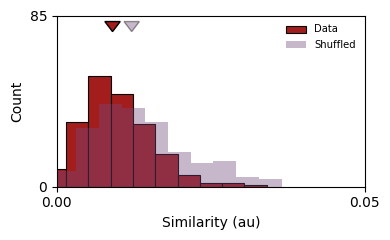

In [18]:
plot_xlim = [0,.05]
plot_ylim = [0,85]
plot_trans = 1
plot_edgecolor = [0,0,0]
figure_size = np.array((4,2.5)) * 1
plot_edgewidth = figure_size[0]*.2
fig_lw = figure_size[0]*.5
save_fig = 0

plt.figure(figsize=figure_size)

plt.hist(rsa_coh_wc, color=color_ob_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='Data')
plt.hist(rsa_coh_shuff_wc, color=color_mpfc_n, alpha=plot_trans-.6, label='Shuffled')

plt.arrow(np.nanmedian(rsa_coh_wc), 82, 0, -.0001, head_length=5, head_width=0.01/4, ec=plot_edgecolor, color=color_ob_n)
plt.arrow(np.nanmedian(rsa_coh_shuff_wc), 82, 0, -.0001, head_length=5, head_width=0.01/4, ec=None, color=color_mpfc_n, alpha=plot_trans-.6)

plt.xlim(plot_xlim)
plt.xticks(plot_xlim)
plt.xlabel('Similarity (au)')

plt.ylim(plot_ylim)
plt.yticks(plot_ylim)
plt.ylabel('Count')

plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper right', fontsize=figure_size[0]*1.8)
clear_output()

print(f"Data: WC Similarity (median-+sd): {np.nanmedian(rsa_coh_wc).round(4)} -+ {np.nanstd(rsa_coh_wc).round(4)}")
print(f"Shuffled: WC Similarity (median-+sd): {np.nanmedian(rsa_coh_shuff_wc).round(4)} -+ {np.nanstd(rsa_coh_shuff_wc).round(4)}")
print(f"WC Permutation p-val: {comp_permute_p(rsa_coh_wc, rsa_coh_shuff_wc)}")
print(f"WC d-prime: {compute_dprime(rsa_coh_wc, rsa_coh_shuff_wc)}")

if save_fig: plt.savefig(f'{FigDir}coh_rsa_wc.svg')

# RSA: Task vs. Baseline

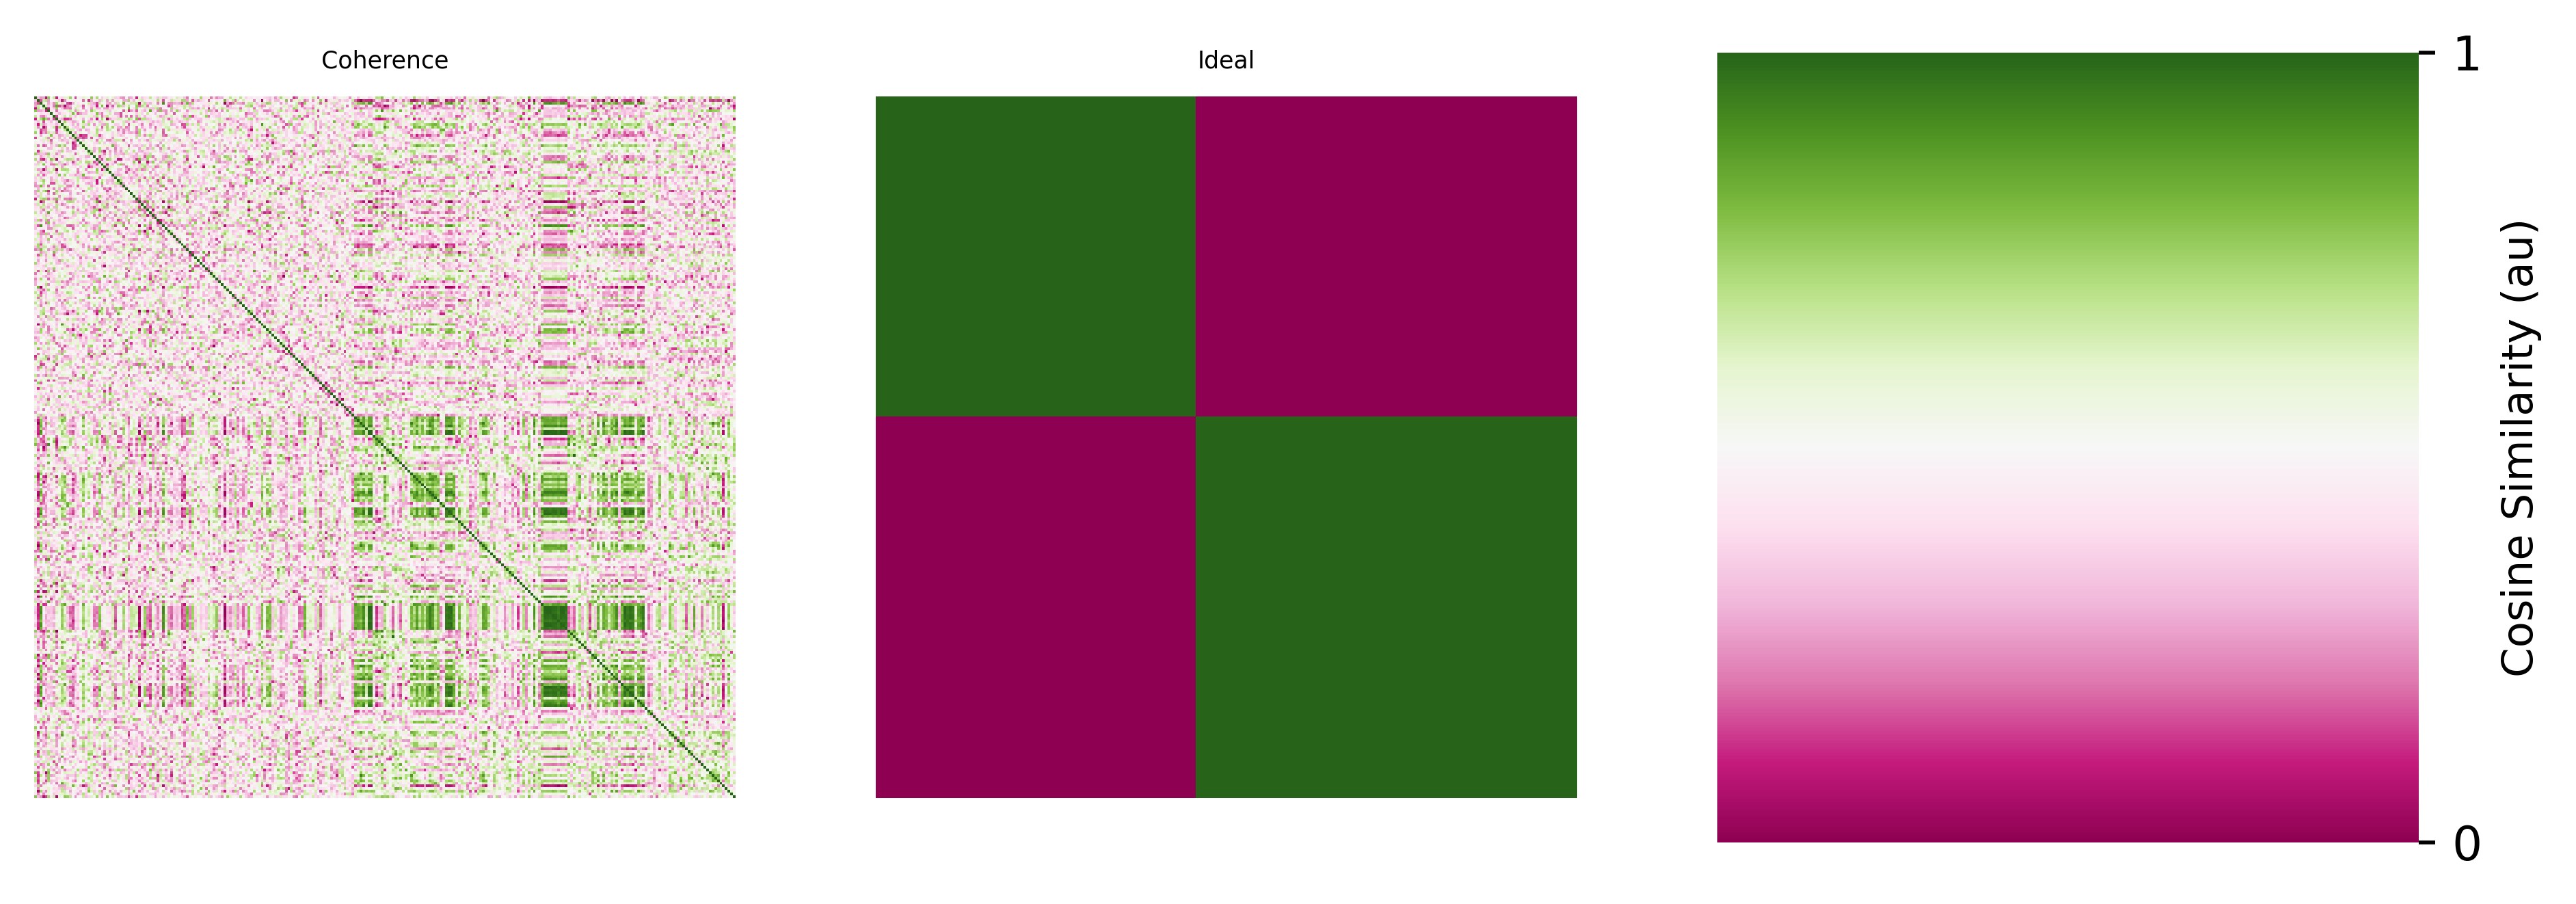

In [4]:
save_fig = 0

rsm_coh_bt = mk_repmat_data(coh_bt.T)
plot_repmat([rsm_coh_bt, mk_repmat_kernel([(idx_bt==1).sum(), (idx_bt==2).sum()])]
            , plot_sz=3, colormap='PiYG', show_clb=True, titles=['Coherence', 'Ideal'])

if save_fig: plt.savefig(f'{FigDir}coh_rsm_bt.svg')

In [5]:
rsa_coh_bt = np.zeros(cycle_num) * np.nan
rsa_coh_shuff_bt = np.copy(rsa_coh_bt)

for iCycle in tqdm(range(cycle_num)):
    rsa_coh_bt[iCycle]       = compute_similarity(mk_repmat_data(coh_bt[idx_rand_bt[iCycle],:].T), mk_repmat_kernel([tr_num,tr_num]))
    rsa_coh_shuff_bt[iCycle] = compute_similarity(mk_repmat_data(coh_bt[idx_rand_shuff_bt[iCycle],:].T), mk_repmat_kernel([tr_num,tr_num]))


  0%|          | 0/200 [00:00<?, ?it/s]

Datat: BT Similarity (median-+sd): 0.1 -+ 0.02
Shuffled: BT Similarity (median-+sd): 0.01 -+ 0.01
BT Permutation p-val: 1.999960000799984e-05
BT d-prime: 4.557675672402521


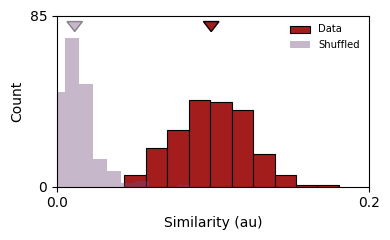

In [19]:
plot_xlim = [0,.2]
plot_ylim = [0,85]
plot_trans = 1
plot_edgecolor = [0,0,0]
figure_size = np.array((4,2.5)) * 1
plot_edgewidth = figure_size[0]*.2
fig_lw = figure_size[0]*.5
save_fig = 0

plt.figure(figsize=figure_size)

plt.hist(rsa_coh_bt, color=color_ob_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='Data')
plt.hist(rsa_coh_shuff_bt, color=color_mpfc_n, alpha=plot_trans-.6, label='Shuffled')

plt.arrow(np.nanmedian(rsa_coh_bt), 82, 0, -.0001, head_length=5, head_width=0.01, ec=plot_edgecolor, color=color_ob_n)
plt.arrow(np.nanmedian(rsa_coh_shuff_bt), 82, 0, -.0001, head_length=5, head_width=0.01, ec=None, color=color_mpfc_n, alpha=plot_trans-.6)

plt.xlim(plot_xlim)
plt.xticks(plot_xlim)
plt.xlabel('Similarity (au)')

plt.ylim(plot_ylim)
plt.yticks(plot_ylim)
plt.ylabel('Count')

plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper right', fontsize=figure_size[0]*1.8)

print(f"Datat: BT Similarity (median-+sd): {np.nanmedian(rsa_coh_bt).round(2)} -+ {np.nanstd(rsa_coh_bt).round(2)}")
print(f"Shuffled: BT Similarity (median-+sd): {np.nanmedian(rsa_coh_shuff_bt).round(2)} -+ {np.nanstd(rsa_coh_shuff_bt).round(2)}")
print(f"BT Permutation p-val: {comp_permute_p(rsa_coh_bt, rsa_coh_shuff_bt)}")
print(f"BT d-prime: {compute_dprime(rsa_coh_bt, rsa_coh_shuff_bt)}")

# clear_output()
if save_fig: plt.savefig(f'{FigDir}coh_rsa_bt.svg')

# RSA: Task vs. Other

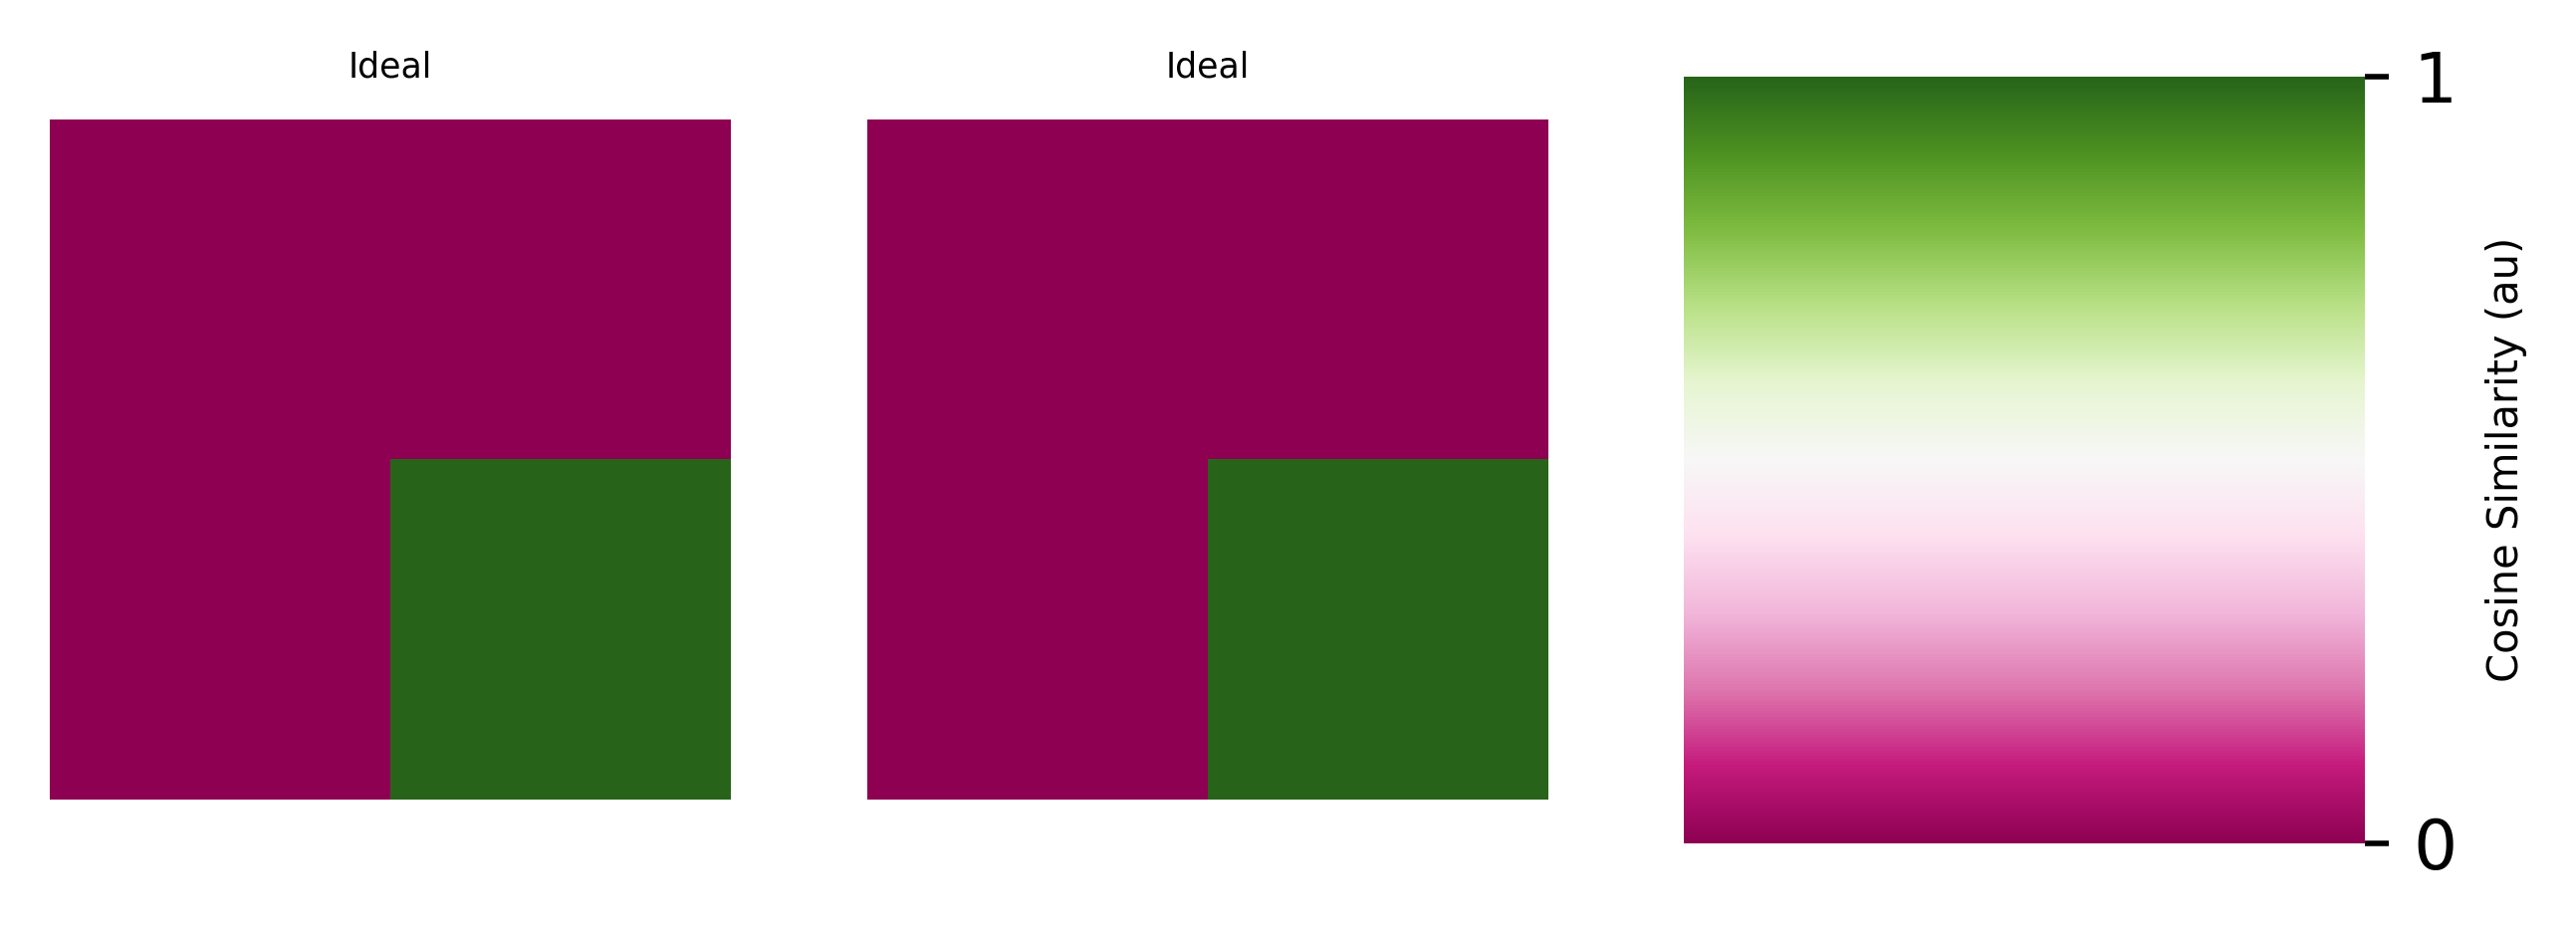

In [4]:
save_fig = 0
fig_sz = 2

coh_rsm_tasknotask = mk_repmat_kernel([tr_num, tr_num])
coh_rsm_tasknotask[:tr_num] = 0

plot_repmat([coh_rsm_tasknotask, coh_rsm_tasknotask], plot_sz=fig_sz, colormap='PiYG', show_clb=True, titles=['Ideal', 'Ideal'])

if save_fig: plt.savefig(f'{FigDir}coh_rsm_tasknotask.svg')

In [5]:
rsa_coh_tasknotask = np.zeros(cycle_num) * np.nan
rsa_coh_shuff_tasknotask = np.copy(rsa_coh_tasknotask)

for iCycle in tqdm(range(cycle_num)):
    rsa_coh_tasknotask[iCycle]       = compute_similarity(mk_repmat_data(coh_bt[idx_rand_bt[iCycle],:].T), coh_rsm_tasknotask)
    rsa_coh_shuff_tasknotask[iCycle] = compute_similarity(mk_repmat_data(coh_bt[idx_rand_shuff_bt[iCycle],:].T), coh_rsm_tasknotask)


  0%|          | 0/200 [00:00<?, ?it/s]

Data: Similarity (median-+sd): 0.16 -+ 0.03
Shuffled: Similarity (median-+sd): 0.01 -+ 0.02
Tasknotask Permutation p-val: 1.999960000799984e-05
Tasknotask d-prime: 5.3820162084630265


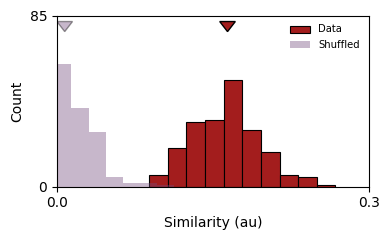

In [12]:
plot_xlim = [0,.3]
plot_ylim = [0,85]
plot_trans = 1
plot_edgecolor = [0,0,0]
figure_size = np.array((4,2.5)) * 1
plot_edgewidth = figure_size[0]*.2
save_fig = 0

plt.figure(figsize=figure_size)

plt.hist(rsa_coh_tasknotask, color=color_ob_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='Data')
plt.hist(rsa_coh_shuff_tasknotask, color=color_mpfc_n, alpha=plot_trans-.6, label='Shuffled')

plt.arrow(np.nanmedian(rsa_coh_tasknotask), 82, 0, -.0001, head_length=5, head_width=0.015, ec=plot_edgecolor, color=color_ob_n)
plt.arrow(np.nanmedian(rsa_coh_shuff_tasknotask), 82, 0, -.0001, head_length=5, head_width=0.015, ec=None, color=color_mpfc_n, alpha=plot_trans-.6)

plt.xlim(plot_xlim)
plt.xticks(plot_xlim)
plt.xlabel('Similarity (au)')

plt.ylim(plot_ylim)
plt.yticks(plot_ylim)
plt.ylabel('Count')

plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper right', fontsize=figure_size[0]*1.8)

print(f"Data: Similarity (median-+sd): {np.nanmedian(rsa_coh_tasknotask).round(2)} -+ {np.nanstd(rsa_coh_tasknotask).round(2)}")
print(f"Shuffled: Similarity (median-+sd): {np.nanmedian(rsa_coh_shuff_tasknotask).round(2)} -+ {np.nanstd(rsa_coh_shuff_tasknotask).round(2)}")
print(f"Tasknotask Permutation p-val: {comp_permute_p(rsa_coh_tasknotask, rsa_coh_shuff_tasknotask)}")
print(f"Tasknotask d-prime: {compute_dprime(rsa_coh_tasknotask, rsa_coh_shuff_tasknotask)}")

# clear_output()
if save_fig: plt.savefig(f'{FigDir}coh_rsa_tasknotask.svg')